# Where the light goes: from an SLM phase pattern to the focal plane

**Question:** Where in the focal plane does a phase pattern on the SLM send the light, and what limits the size of the field and the power that reaches a trap?

- **Level:** 1, Fundamentals
- **Prerequisites:** none, this is the entry notebook of the set
- **Reading time:** about 40 minutes

## Objectives

A holographic optical trap array starts from one fact: a liquid-crystal SLM changes the phase of a laser beam pixel by pixel, a lens turns that phase into a pattern of light in its focal plane, and every trap is a bright spot of that pattern. Every method of the later notebooks only chooses the phase. This notebook explains what that phase does, with the engine of the product and one real case. By the end you can predict where a blazed grating puts its spot, say how wide the usable window is and what happens beyond it, estimate how much a trap loses to the pixel aperture, and read where the power of a hologram goes when the SLM has few phase levels or a nonlinear response.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. The next cell imports the tools, prints their versions and puts the pipeline on the path.

In [1]:
# the tools and their versions, then the pipeline's modules by path
import importlib.metadata as md
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, geometry, metrics, modes
from pipeline.model.holo.core.device import Device, device_focal_field, pixel_envelope
from pipeline.model.holo.core.traps import OutOfFieldError, Trap, TrapSet

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2


## Data

The notebook needs only the optical setup of one case, no measured sample.

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic parameters written by the product (no third-party dataset), covered by the repository licence.
- File read: `data/examples/cases.json`, case C01 (850 nm laser, 6 mm focal length, 256 by 256 pixels of 20 um, Gaussian beam).

In [2]:
# case C01 supplies the optical setup; only its setup block is used here
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
setup = setup_of(records["C01_square_grid"])
print("wavelength", setup.wavelength_m * 1e9, "nm,", "focal length", setup.focal_m * 1e3, "mm")
print("SLM", setup.n_pix, "x", setup.n_pix, "pixels of", setup.pitch_m * 1e6, "um; FFT", setup.n_fft, "x", setup.n_fft)

wavelength 850.0 nm, focal length 6.0 mm
SLM 256 x 256 pixels of 20.0 um; FFT 512 x 512


## Method

Take an SLM of $N \times N$ pixels with pitch $p$ lit by a beam of amplitude $A_j$, and let $\phi_j$ be the phase it shows. A lens of focal length $f$ one focal length behind the SLM produces in its focal plane the Fraunhofer transform of the SLM field, so the field at the focal-plane point $(x, y)$ is proportional to $\sum_j A_j e^{i\phi_j} e^{-2\pi i (x x_j + y y_j)/(\lambda f)}$. A trap $m$ at $(x_m, y_m)$ receives the power fraction $I_m = |V_m|^2$ with $V_m = \frac{1}{N^2}\sum_j A_j e^{i(\phi_j - \Delta_j^m)}$ and $\Delta_j^m = \frac{2\pi}{\lambda f}(x_j x_m + y_j y_m)$ for a trap in the focal plane (Di Leonardo et al. 2007, Eqs. 1 to 4, https://doi.org/10.1364/OE.15.001913). The engine evaluates this sum directly, and also with a zero-padded fast Fourier transform on a grid of $\mathrm{pad}\,N$ bins. The five steps below follow the light from the sampling of the focal plane to the losses of a real device.

The focal plane is sampled by the transform, so the first thing to know is the grid. One bin of the padded transform is $\lambda f/(\mathrm{pad}\,N p)$ wide, and the grid spans exactly one period $\lambda f/p$ of the replicas that the pixel sampling creates, so the unaliased half window is $\lambda f/(2p)$ (the bin follows Schroff et al. 2023, https://doi.org/10.1038/s41598-023-30296-6; the half window is derived from it in the product's research record). The cell prints these three lengths for case C01, and the largest power a single trap can get: with a Gaussian beam clipped by a square SLM, the field of one trap is the mean of the amplitude $A_j$, so its power is at most $\bar A^2$.

In [3]:
# the sampling of the focal plane: one bin, the half window and the replica period
bin_m = geometry.focal_bin_m(setup)
bin_um = bin_m * 1e6
half_um = geometry.half_field_m(setup) * 1e6
print(f"focal bin {bin_um:.4f} um, half window {half_um:.2f} um, replica period {2 * half_um:.2f} um")
ceiling = geometry.input_amplitude(setup).mean() ** 2
print(f"one trap alone can receive at most the square of the mean amplitude of the beam, (mean A)^2 = {ceiling:.4f}")

focal bin 0.4980 um, half window 127.50 um, replica period 255.00 um
one trap alone can receive at most the square of the mean amplitude of the beam, (mean A)^2 = 0.8695


Now a hologram. A linear phase ramp, a blazed grating, sends the light to one place: $\phi_j = \frac{2\pi}{\lambda f}(x_j x_m + y_j y_m)$ wrapped to $[0, 2\pi)$. The next cell builds that ramp for a spot 40 bins to the right of the axis, transforms it to the focal plane and finds the brightest bin. Light that reaches the focal plane at the requested place, with the power fraction the previous cell predicted, shows that the geometry of the engine is the geometry of the equations.

In [4]:
# a blazed grating that should send all the light to a trap 40 bins to the right of the axis
centre = setup.n_fft // 2
x_trap = 40 * bin_m
phi = modes.grating_phase(setup, x_trap, 0.0)
field = forward.fft_focal_field(phi, setup)
power = np.abs(field) ** 2 * setup.pad**2 / setup.n_pix**2
iy, ix = np.unravel_index(np.argmax(power), power.shape)
print(f"peak at x = {(ix - centre) * bin_um:.3f} um, y = {(iy - centre) * bin_um:.3f} um")
print(f"requested x = {x_trap * 1e6:.3f} um")
print(f"power in the peak, as a fraction of the input power: {power[iy, ix]:.4f}")

peak at x = 19.922 um, y = 0.000 um
requested x = 19.922 um
power in the peak, as a fraction of the input power: 0.8695


The engine has two ways to read a trap. The point-trap form sums over the SLM pixels exactly as the equation of the Method section says; the FFT form reads the transformed grid at the nearest bin. They must agree for a trap that sits on a bin, because the second form is the first evaluated on the grid. The cell compares the two for the trap just built.

In [5]:
# the same trap read with the point-trap sum and from the FFT grid
traps = TrapSet([Trap(0, x_trap, 0.0)])
v_point = forward.point_trap_fields(phi, setup, traps)
v_fft = forward.trap_fields_from_fft(field, setup, traps)
print("point-trap form |V|^2:", np.abs(v_point) ** 2, "FFT form |V|^2:", np.abs(v_fft) ** 2)
print("largest difference of the two V:", float(np.abs(v_point - v_fft).max()))

point-trap form |V|^2: [0.86948925] FFT form |V|^2: [0.86948925]
largest difference of the two V: 2.699599995149934e-16


The next figure shows the two sides of the transform for that grating: the central pixels of the hologram, a sawtooth of stripes whose pitch fixes the angle, and the power in the focal plane on a logarithmic scale, so that faint structure is visible.

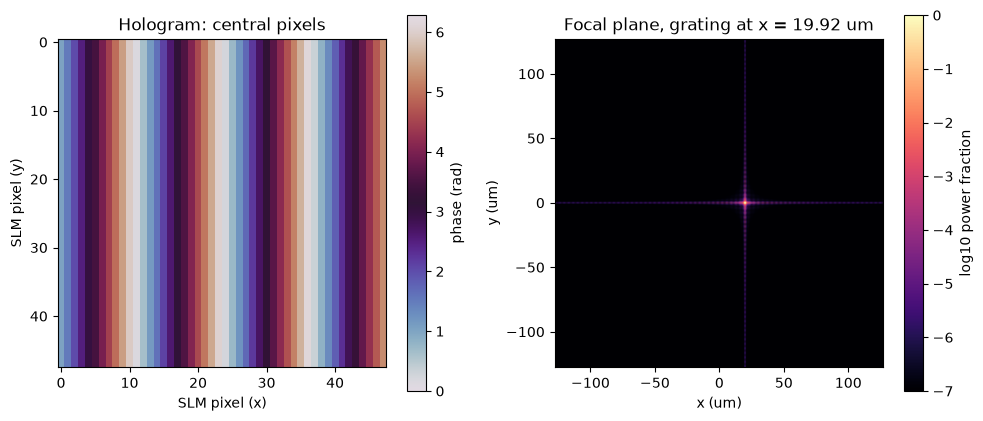

In [6]:
# left: the central 48 x 48 pixels of the hologram; right: the focal power on a log scale
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.3))
c = setup.n_pix // 2
im1 = ax1.imshow(phi[c - 24:c + 24, c - 24:c + 24], cmap="twilight", vmin=0, vmax=2 * np.pi)
ax1.set_title("Hologram: central pixels")
ax1.set_xlabel("SLM pixel (x)")
ax1.set_ylabel("SLM pixel (y)")
fig.colorbar(im1, ax=ax1, label="phase (rad)")
ext = [-half_um - bin_um / 2, half_um - bin_um / 2] * 2
im2 = ax2.imshow(np.log10(power + 1e-9), origin="lower", extent=ext, vmin=-7, vmax=0, cmap="magma")
ax2.set_title("Focal plane, grating at x = 19.92 um")
ax2.set_xlabel("x (um)")
ax2.set_ylabel("y (um)")
fig.colorbar(im2, ax=ax2, label="log10 power fraction")
fig.tight_layout()
plt.show()

The hologram is a set of straight stripes; each stripe is one full turn of phase, and nearly four of them fit in the 48 pixels shown, which is the angle that sends the spot about 20 um from the axis. The focal plane holds one bright spot at that place and, on the log scale, a cross of faint tails along the two axes: they come from the square edge of the SLM and from the Gaussian clipping, and they are not noise, since the computation has none. The figure does not show the spot's width, which is set by the aperture of the SLM and is about two bins, nor any imperfection of a real SLM; the next steps add those.

How far from the axis can a trap be? The grid has a finite window, and the transform is periodic, so a spot requested beyond the half window cannot appear outside it. The cell asks for gratings that put a spot at 100, 140 and 200 um and prints where the brightest bin is. Because the replicas repeat with period $\lambda f/p$, a spot at $x$ beyond $\lambda f/(2p)$ appears at $x - \lambda f/p$, and the cell checks that on the middle request.

In [7]:
# a trap beyond the half window: the FFT form folds it back onto the grid
cuts = {}
for x_um in (100.0, 140.0, 200.0):
    phi_far = modes.grating_phase(setup, x_um * 1e-6, 0.0)
    power_far = np.abs(forward.fft_focal_field(phi_far, setup)) ** 2 * setup.pad**2 / setup.n_pix**2
    cuts[x_um] = power_far[centre]
    seen = (np.argmax(cuts[x_um]) - centre) * bin_um
    print(f"asked {x_um:6.1f} um -> found {seen:8.2f} um")

asked  100.0 um -> found   100.11 um
asked  140.0 um -> found  -115.05 um
asked  200.0 um -> found   -54.79 um


A trap outside the window is not a hologram that is slightly worse: it is a request that cannot be met, because the real replica lands somewhere else. The point-trap form therefore refuses it with a message that names the trap and the bound. The cell asks for the trap at 140 um and prints the refusal.

In [8]:
# the point-trap form refuses the same trap and says why
try:
    forward.point_trap_fields(phi_far, setup, TrapSet([Trap(0, 140e-6, 0.0)]))
except OutOfFieldError as err:
    print(err)

trap 0 has x = 1.400e-04 m, outside the unaliased field of view (bound = 1.275e-04 m = lambda f / (2 p))


The cuts of the three holograms along the axis show the same thing graphically. Dotted lines mark the edges of the window at plus and minus $\lambda f/(2p)$.

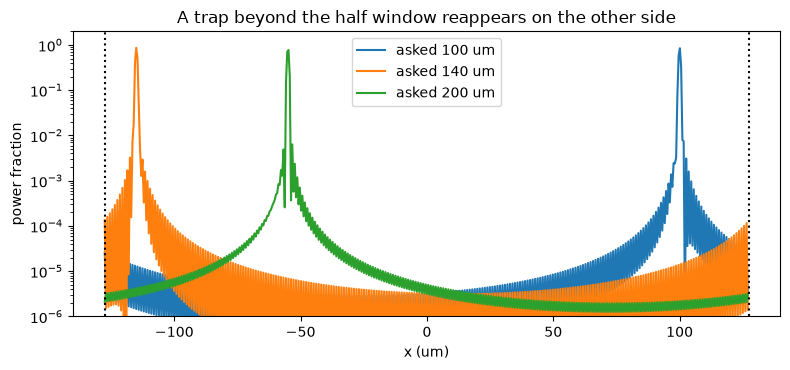

In [9]:
# the cut along y = 0 of the three holograms, on a log scale, with the window edges marked
fig, ax = plt.subplots(figsize=(8, 3.8))
axis = (np.arange(setup.n_fft) - centre) * bin_um
for x_um, cut in cuts.items():
    ax.semilogy(axis, cut + 1e-9, label=f"asked {x_um:.0f} um")
ax.axvline(-half_um, color="k", ls=":")
ax.axvline(half_um, color="k", ls=":")
ax.set_ylim(1e-6, 2)
ax.set_xlabel("x (um)")
ax.set_ylabel("power fraction")
ax.set_title("A trap beyond the half window reappears on the other side")
ax.legend()
fig.tight_layout()
plt.show()

The spot requested at 100 um sits inside the window and appears where it was asked. The spot requested at 140 um appears at the mirror-symmetric place near minus 115 um, which is 140 minus the period of 255 um; the one requested at 200 um appears at about minus 55 um for the same reason. On the real device the replica is physical light that travels with the trap, so the usable field is the window of width $\lambda f/p$ and not more. The figure does not tell how much power the replicas carry (that is the pixel envelope below), nor how the window changes with the lens: it scales with $f/p$ and with the wavelength.

The pixel itself has a size. A square pixel of width $a = \sqrt{\text{fill}}\,p$ multiplies the focal field by $\mathrm{sinc}(a x/(\lambda f))\,\mathrm{sinc}(a y/(\lambda f))$, so the power of a trap falls with its distance from the axis (derived in the product's research record and checked there against a brute-force transform). The cell moves a grating trap from the axis to the last bin of the window, measures its peak power with the pixel aperture of a device with fill factor 1 and without it, and prints the ratio next to the formula `pixel_envelope`. Both must agree, because the second is the closed form of the first.

In [10]:
# the peak power of a grating trap with and without the pixel aperture, against its position
bins = np.append(np.arange(0, 256, 16), 255)
ratio = []
for k in bins:
    phi_k = modes.grating_phase(setup, k * bin_m, 0.0)
    ideal = np.abs(forward.fft_focal_field(phi_k, setup)[centre, centre + k]) ** 2
    real = np.abs(device_focal_field(phi_k, setup, Device(), None)[centre, centre + k]) ** 2
    ratio.append(real / ideal)
envelope = pixel_envelope(setup, Device())[centre, centre:]
for k, r in list(zip(bins, ratio))[::4]:
    print(f"x = {k * bin_um:6.1f} um  measured ratio {r:.4f}  formula {envelope[k]:.4f}")
print(f"ratio at the last bin, formula: {envelope[255]:.4f}")

x =    0.0 um  measured ratio 1.0000  formula 1.0000
x =   31.9 um  measured ratio 0.9496  formula 0.9496
x =   63.8 um  measured ratio 0.8106  formula 0.8106
x =   95.6 um  measured ratio 0.6150  formula 0.6150
x =  127.0 um  measured ratio 0.4085  formula 0.4085
ratio at the last bin, formula: 0.4085


The figure draws the measured ratios as dots over the formula as a line.

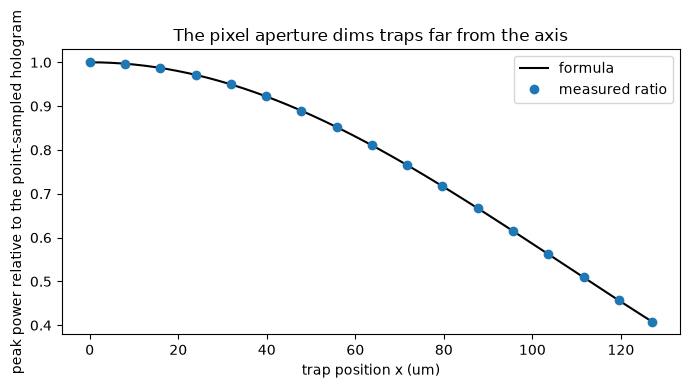

In [11]:
# measured ratio (dots) on the formula sinc^2(sqrt(fill) k / n_fft)^2 (line)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(np.arange(256) * bin_um, envelope, "k-", label="formula")
ax.plot(bins * bin_um, ratio, "o", label="measured ratio")
ax.set_xlabel("trap position x (um)")
ax.set_ylabel("peak power relative to the point-sampled hologram")
ax.set_title("The pixel aperture dims traps far from the axis")
ax.legend()
fig.tight_layout()
plt.show()

The dots lie on the line over the whole window: a trap at 64 um from the axis keeps about 0.81 of its power and a trap at the last bin keeps about 0.41, the intensity of the formula at the edge being $\mathrm{sinc}^2(1/2)$. This is a loss of the device, not of the algorithm, and the hologram cannot fix it unless it asks for more power in the outer traps, which later notebooks do with weights. The figure assumes a fill factor of 1 (no dead area between pixels) and square pixels; a fill factor below 1 raises the envelope, because the aperture is smaller, but the dead area then wastes input power that this model does not count.

The other limit of a real SLM is that its phase has few levels. A staircase of $L = 2^b$ levels replaces the smooth ramp, and for a blazed grating the first order carries a fraction $\mathrm{sinc}^2(1/L)$ of what the smooth ramp would carry (a standard result for a staircase grating, which this notebook checks numerically rather than citing). The cell quantizes the same grating to 1, 2, 3, 4 and 8 bits through the device model, splits the power with `power_budget` into the trap, the zero order, the ghosts and what is left outside the grid, and prints the trap fraction next to the staircase prediction scaled to the 8-bit trap.

In [12]:
# where the power of the same grating goes when the SLM shows 1 to 8 bits
reference = metrics.power_budget(device_focal_field(phi, setup, Device(bit_depth=8), None), setup, traps)
rows = {}
for bits in (1, 2, 3, 4, 8):
    field_q = device_focal_field(phi, setup, Device(bit_depth=bits), None)
    rows[bits] = metrics.power_budget(field_q, setup, traps)
    theory = np.sinc(1 / 2**bits) ** 2 * reference["traps"]
    got = rows[bits]
    print(f"{bits} bit: in the trap {got['traps']:.4f} (staircase theory {theory:.4f})")
    print(f"      in the ghosts {got['ghosts']:.4f}")

1 bit: in the trap 0.3699 (staircase theory 0.3696)
      in the ghosts 0.5666
2 bit: in the trap 0.7399 (staircase theory 0.7393)
      in the ghosts 0.1966
3 bit: in the trap 0.8668 (staircase theory 0.8661)
      in the ghosts 0.0970
4 bit: in the trap 0.9011 (staircase theory 0.9004)
      in the ghosts 0.0759
8 bit: in the trap 0.9121 (staircase theory 0.9120)
      in the ghosts 0.0676


The stacked bars show the same budget for the five bit depths.

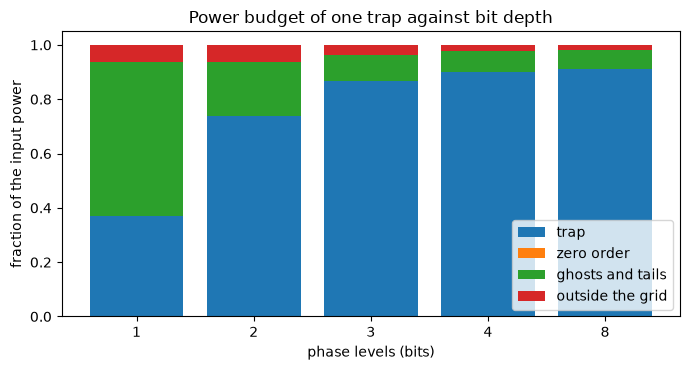

In [13]:
# the power budget as stacked bars, one bar per bit depth
fig, ax = plt.subplots(figsize=(7, 3.8))
labels = {
    "traps": "trap",
    "zero_order": "zero order",
    "ghosts": "ghosts and tails",
    "remainder": "outside the grid",
}
bottom = np.zeros(len(rows))
for part, label in labels.items():
    values = np.array([rows[b][part] for b in rows])
    ax.bar([str(b) for b in rows], values, bottom=bottom, label=label)
    bottom += values
ax.set_xlabel("phase levels (bits)")
ax.set_ylabel("fraction of the input power")
ax.set_title("Power budget of one trap against bit depth")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

With 1 bit the trap holds 0.37 of the input power and the ghosts hold 0.57; with 2 bits the trap holds 0.74; from 4 bits the trap fraction is within 1.2 percent of its 8-bit value of 0.91, and the printed staircase predictions agree with the measured trap fractions to within 0.001. The 8-bit remainder is the aperture and the Gaussian clipping, not the quantization. Power left in the ghosts is not lost for the SLM but it is light where nobody wants it, and in a trap array it adds a background that the weights of the later notebooks cannot remove. The figure assumes an ideal linear phase response; the next cell relaxes that.

A real liquid-crystal pixel does not respond linearly to its command level. `lut_gamma` bends the response as $2\pi (\text{level}/2\pi)^\gamma$, and a pixel that does not give the phase it was told to give leaves a constant component in the field, which is light at the zero order, the bin on the optical axis. The cell raises the exponent from 1 to 1.5 and prints the peak fraction at the zero order and the trap fraction.

In [14]:
# a phase response that is not linear in the level leaks light into the zero order
for gamma in (1.0, 1.1, 1.25, 1.5):
    field_g = device_focal_field(phi, setup, Device(lut_gamma=gamma), None)
    zero = metrics.zero_order_fraction(field_g, setup)
    budget = metrics.power_budget(field_g, setup, traps)
    print(f"gamma {gamma:4.2f}: zero-order peak {zero:.4f}, in the trap {budget['traps']:.4f}")

gamma 1.00: zero-order peak 0.0000, in the trap 0.9121
gamma 1.10: zero-order peak 0.0016, in the trap 0.9083
gamma 1.25: zero-order peak 0.0085, in the trap 0.8916
gamma 1.50: zero-order peak 0.0275, in the trap 0.8458


The peak fraction at the zero order is 0.0016 for an exponent of 1.1, 0.0085 for 1.25 and 0.0275 for 1.5, from a value near zero for the linear device, while the trap loses power from 0.912 to 0.846. The zero order is one more bright spot on the axis, and it competes for the same light as the traps near it. The numbers are those of this device model; the model has no measurement behind its exponent, so the values show the mechanism, not a device.

## Results

**Answer:** The light of a phase pattern lands where its Fourier transform puts it. A blazed grating that asked for a spot 19.92 um from the axis gave its brightest bin at 19.922 um with 0.8695 of the input power, which is the largest a single trap can receive with this Gaussian beam. The bin is 0.498 um and the unaliased window is 127.50 um on each side, so the field is 255.00 um wide: a spot requested at 140 um reappears at minus 115.05 um, and the point-trap form refuses it. Inside the window the pixel aperture costs power with distance, down to 0.41 of the peak at the last bin. The phase levels cost power too: the trap keeps 0.74 of the input with 2 bits and 0.91 from 4 bits on, and a nonlinear response puts up to 0.0275 of the peak on the zero order at an exponent of 1.5. These limits are properties of the SLM and the lens, so every method of the next notebooks works inside them.

## Summary

The focal plane is the transform of the SLM field. A trap sits on a bin of width $\lambda f/(\mathrm{pad}\,Np)$, the window is $\pm\lambda f/(2p)$, and the sampling makes replicas outside it. The pixel aperture multiplies the intensity by a sinc-squared envelope, the finite phase levels move power into ghosts, and a nonlinear response puts light on the axis. The next notebook turns these losses into numbers for a trap array: efficiency, uniformity and the power budget.

## References

- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- Schroff et al., "Accurate holographic light potentials using pixel crosstalk modelling", Scientific Reports 13 (2023), https://doi.org/10.1038/s41598-023-30296-6.